<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [BGP MRT Decoder](https://github.com/Query-farm/vgi-bgp)

Query RouteViews and RIPE RIS MRT archives (RIB snapshots and BGP updates) as SQL rows, with AS-path and community helpers.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-bgp/blob/main/notebooks/02_community_shape_comes_before_policy.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-bgp/blob/main/notebooks/README.md)

## 02 · Community shape comes before policy

**Would parsing only standard communities miss annotations attached to a route?**
A BGP community is a label carried with a route. Its structure helps us select and
group annotations, but its numeric fields alone do not tell us which routing
policy an operator applied. We will classify the worker's built-in synthetic RIB,
select one numeric administrator field, and keep route counts separate from label counts.

The real worker decodes a bundled **synthetic MRT fixture**, not observed Internet
traffic. The three route observations have fixture timestamp **2025-06-29 00:00:00 UTC**.
Separate authored strings test parser boundaries; they do not become route observations.

### Select an administrator field, not a policy interpretation

`SELECTED_ADMIN` is an unsigned 32-bit integer. The default **65001** and experiment
**65002** both occur in the fixture. Selection uses the first numeric component of
either a standard or a large community. We make no claim about actual ownership
or the meaning of the remaining numbers. The full RIB stays fixed.

In [1]:
SELECTED_ADMIN = 65001

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.8":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.8"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme

check_runtime()
prepare("bgp")
import bgp_example as example

example.validate_admin(SELECTED_ADMIN)
session = connect(globals())
theme()

### Decode the built-in sample view once

The v0.4.0 native worker supplies `example_rib` as a browsable view over its tiny
embedded MRT blob. We select columns that exist in both the pinned release and
current source. Current source adds peer IP to this view; the release does not.
This example's three ASN/prefix pairs are unique, which we check before using them
as local row identities. That is not a general substitute for a complete peer key.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL inet FROM core;
LOAD inet;
ATTACH 'bgp' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-bgp@v0.4.0');
CREATE TABLE sample_routes AS
SELECT timestamp AS observed_at,peer_asn,prefix::INET::VARCHAR AS prefix,
       as_path,communities
FROM bgp.main.example_rib;

,Count


In [5]:
%%sql routes <<
SELECT * FROM sample_routes ORDER BY peer_asn,prefix;

In [6]:
example.community_preview(routes)

,observed_at,peer_asn,prefix,as_path,communities
0,2025-06-29,65001,2001:db8:abcd::/48,"[65001, 64500, 64600]",[65001:7:9]
1,2025-06-29,65001,203.0.113.0/24,"[65001, 64500, 64500, 64512]","[65001:100, 65001:1:2]"
2,2025-06-29,65002,203.0.113.0/24,"[65002, 64513, 64512]",[65002:200]


The built-in view returns **3 synthetic route observations** with **4 community strings**. The release view lacks peer IP, so this story uses only its shared ASN/prefix/path/communities projection. The paired notebook reads MRT files directly when it needs the full peer IP + ASN key.

### Classify each label before applying a numeric filter

Unnest the community lists while retaining each route's identity. `community_parse`
returns a struct for two numeric parts and NULL for other shapes. `is_large_community`
recognizes three unsigned numeric parts. Only after that classification do we use
SQL to extract the first field from a large community. A NULL standard parse is
therefore not evidence that a valid large community is missing.

The selection below does not decode an operator's policy dictionary. In particular,
a label's first component is not automatically the origin ASN or reporting peer.

The formats are defined in [RFC 1997](https://www.rfc-editor.org/rfc/rfc1997)
and [RFC 8092](https://www.rfc-editor.org/rfc/rfc8092). The latter separates
one global administrator field from two locally defined data fields.

In [7]:
%%sql
CREATE TABLE annotations AS
WITH labels AS (
 SELECT peer_asn,prefix,unnest(communities) AS raw FROM sample_routes
), parsed AS (
 SELECT *,bgp.main.community_parse(raw) AS standard,
          bgp.main.is_large_community(raw) AS is_large
 FROM labels
)
SELECT *,CASE WHEN is_large THEN 'Large'
              WHEN standard IS NOT NULL THEN 'Standard' ELSE 'Other' END AS shape,
       CASE WHEN is_large THEN try_cast(split_part(raw,':',1) AS UINTEGER)
            WHEN standard IS NOT NULL THEN standard.asn END AS admin
FROM parsed;
CREATE TABLE selected_labels AS
SELECT * FROM annotations WHERE admin={{ SELECTED_ADMIN }};

,Count


In [8]:
%%sql annotation_frame <<
SELECT peer_asn,prefix,raw,standard,is_large,shape,admin
FROM annotations ORDER BY peer_asn,prefix,raw;

In [9]:
%%sql selected_frame <<
SELECT peer_asn,prefix,raw,shape FROM selected_labels ORDER BY peer_asn,prefix,raw;

In [10]:
%%sql summary <<
SELECT (SELECT count(*) FROM sample_routes) AS all_routes,
       (SELECT count(*) FROM selected_labels) AS selected_labels,
       (SELECT count(DISTINCT (peer_asn,prefix)) FROM selected_labels) AS selected_routes,
       (SELECT count(DISTINCT (peer_asn,prefix)) FROM selected_labels WHERE shape='Standard') AS standard_only_routes;

In [11]:
example.community_finding(annotation_frame, selected_frame, summary, SELECTED_ADMIN)

,peer_asn,prefix,raw,standard,is_large,shape,admin
0,65001,2001:db8:abcd::/48,65001:7:9,<NA>,True,Large,65001
1,65001,203.0.113.0/24,65001:100,"{'asn': 65001, 'value': 100}",False,Standard,65001
2,65001,203.0.113.0/24,65001:1:2,<NA>,True,Large,65001
3,65002,203.0.113.0/24,65002:200,"{'asn': 65002, 'value': 200}",False,Standard,65002


,peer_asn,prefix,raw,shape
0,65001,2001:db8:abcd::/48,65001:7:9,Large
1,65001,203.0.113.0/24,65001:100,Standard
2,65001,203.0.113.0/24,65001:1:2,Large


Selecting first numeric component **65001** retains **3 labels** on **2 of 3 route observations**. Only **1** of those observations would be found by parsing standard two-part communities alone. A NULL standard parse can mean a valid large community; it does not mean the annotation is absent. The numeric fields are not an operator's policy dictionary.

In [12]:
%%sql matrix_frame <<
SELECT 'AS'||r.peer_asn||' · '||r.prefix AS route_label,s.shape,count(a.raw) AS label_count
FROM sample_routes r CROSS JOIN (VALUES ('Standard'),('Large')) s(shape)
LEFT JOIN annotations a ON a.peer_asn=r.peer_asn AND a.prefix=r.prefix AND a.shape=s.shape
GROUP BY ALL ORDER BY route_label,s.shape;

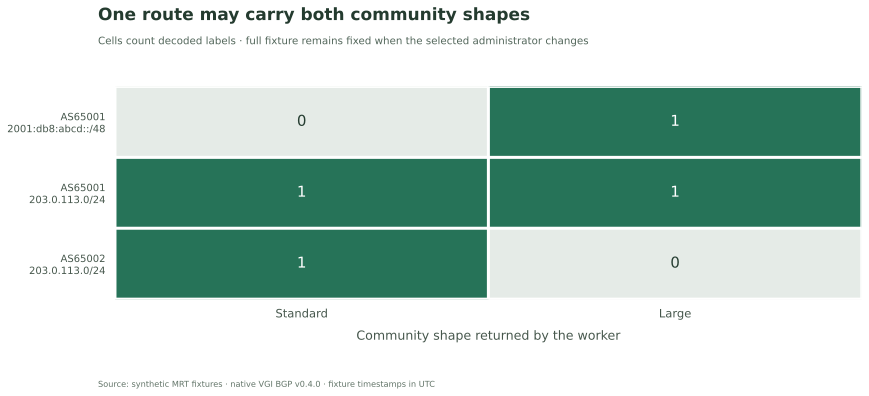

In [13]:
example.community_chart(matrix_frame, SELECTED_ADMIN)

### A parser result is not a complete wire-format or policy validator

These three **authored diagnostic strings** are separate from the decoded fixture.
A well-known mnemonic, malformed text and an oversized standard field each test a
different boundary. Keep the original string next to the parser result so that
NULL does not silently become an absent label or a zero-valued field.

In [14]:
%%sql diagnostics <<
SELECT raw,bgp.main.community_parse(raw) AS standard,
       bgp.main.is_large_community(raw) AS is_large
FROM (VALUES ('NO_EXPORT'),('not:a:number'),('65536:1')) t(raw);

In [15]:
example.diagnostics_finding(diagnostics)

,raw,standard,is_large
0,NO_EXPORT,<NA>,False
1,not:a:number,<NA>,False
2,65536:1,"{'asn': 65536, 'value': 1}",False


`NO_EXPORT` is not a two-part numeric community and is not a large community; its NULL parse does not erase its well-known meaning. The malformed control also stays unparsed. The worker accepts `65536:1` as two unsigned 32-bit numbers: this parser alone does not enforce the 16-bit field widths of a standard wire community. These controls are authored strings, not additional MRT observations, and none proves that an export policy was applied.

### Check the population and classification contract

The route population stays fixed before filtering labels. Valid large labels
must not also parse as two-part labels, and every selected label must trace back
to the complete annotation table. The local row key is checked explicitly.

In [16]:
%%sql checks <<
SELECT 'Unique local ASN/prefix keys' AS check_name,
 count(*)=count(DISTINCT (peer_asn,prefix)) AS passed FROM sample_routes
UNION ALL SELECT 'Nonempty route population',count(*)>0 FROM sample_routes
UNION ALL SELECT 'Every label has one recognized fixture shape',bool_and(shape IN ('Standard','Large')) FROM annotations
UNION ALL SELECT 'Large labels are not standard parses',bool_and(standard IS NULL) FROM annotations WHERE is_large
UNION ALL SELECT 'Selection is a subset of decoded labels',NOT EXISTS(SELECT * FROM selected_labels EXCEPT SELECT * FROM annotations)
UNION ALL SELECT 'Every route has labels in this fixture',bool_and(len(communities)>0) FROM sample_routes
UNION ALL SELECT 'Selected component matches parameter',NOT EXISTS(SELECT 1 FROM selected_labels WHERE admin IS DISTINCT FROM {{ SELECTED_ADMIN }});

In [17]:
example.community_checks(checks)

,check_name,passed
0,Unique local ASN/prefix keys,True
1,Nonempty route population,True
2,Every label has one recognized fixture shape,True
3,Large labels are not standard parses,True
4,Selection is a subset of decoded labels,True
5,Every route has labels in this fixture,True
6,Selected component matches parameter,True


**All 7 population and classification checks passed.** Routes with no selected labels remain in the denominator. The example describes annotation shape and membership, not policy enforcement.

### Experiment: select 65002

Change only **`SELECTED_ADMIN = 65002`**, restart and run all. Predict which labels
remain and compare selected-label count with selected-route count. The full RIB,
shape grid and parser diagnostics must stay fixed. An administrator absent from
the fixture should yield an empty selection, not a smaller source population.

No community dictionary, router configuration or export observation is present.
These results establish label structure and membership only. Reset to **65001**
for the saved default; use the [runner](README.md) to save the experiment separately.

In [18]:
con.execute("DETACH bgp")
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-bgp](https://github.com/Query-farm/vgi-bgp)
